<a href="https://colab.research.google.com/github/Amw839/CSCE625_HW8_DeepLearning_XOR_MNIST_AmiraWallace/blob/main/interpreting%20what%20convolutional%20network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSCE 636 – Homework 5
## Interpreting What Convolutional Neural Networks Learn

**Student:** Amira Wallace

### Objective
In this homework, I explored three methods for understanding what a convolutional neural network learns internally:

1. Visualizing intermediate activations
2. Visualizing convolutional filters
3. Visualizing class activation heatmaps using Grad-CAM

I used a pretrained VGG16 model because it already contains convolutional filters learned from a large image dataset. The goal is not to retrain the model, but to inspect how it processes images and what parts of an image influence its prediction.


## Setup

The following cell imports the libraries needed for the homework. I use TensorFlow/Keras for the pretrained VGG16 model and Matplotlib for the visualizations.


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random

from tensorflow import keras
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image
from tensorflow.keras.utils import get_file

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## Load the pretrained VGG16 model

VGG16 is a convolutional neural network trained on ImageNet. Since it is already trained, I can inspect its learned filters and activations directly.


In [2]:
model = VGG16(weights="imagenet")
model.summary()


553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

## Load a sample image

For this homework, I use a publicly available cat image. The image is resized to 224 × 224 pixels because that is the input size expected by VGG16.


17858/17858 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


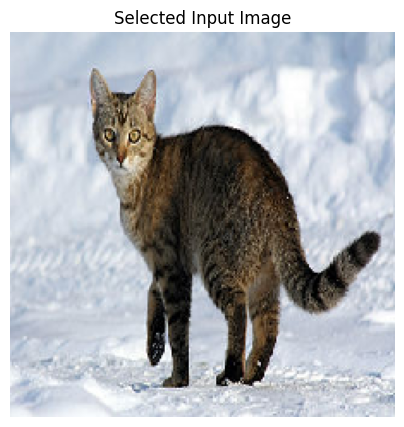

In [3]:
img_path = get_file(
    "sample_cat.jpg",
    origin="https://storage.googleapis.com/download.tensorflow.org/example_images/320px-Felis_catus-cat_on_snow.jpg"
)

img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title("Selected Input Image")
plt.show()


# Part 1 – Visualizing Intermediate Activations

In this section, I visualize the outputs produced by different convolutional layers of VGG16.

A convolutional neural network does not process an image in only one step. Each layer transforms the image into a new representation. Early layers usually respond to simple features such as edges, lines, and color contrasts. Deeper layers respond to more complex patterns and object parts.

To observe this process, I create a new model that returns the outputs of selected intermediate convolutional layers.


In [4]:
layer_names = [
    "block1_conv1",
    "block2_conv1",
    "block3_conv1",
    "block4_conv1",
    "block5_conv1"
]

layer_outputs = [model.get_layer(name).output for name in layer_names]

activation_model = keras.Model(
    inputs=model.input,
    outputs=layer_outputs
)

input_array = np.expand_dims(img_array.copy(), axis=0)
input_array = preprocess_input(input_array)

activations = activation_model.predict(input_array, verbose=0)

print("Intermediate activations generated.")


Intermediate activations generated.


### Display selected feature maps

Each layer contains many channels, or feature maps. I display several channels from each selected layer so I can compare how the representation changes as the image moves deeper into the network.


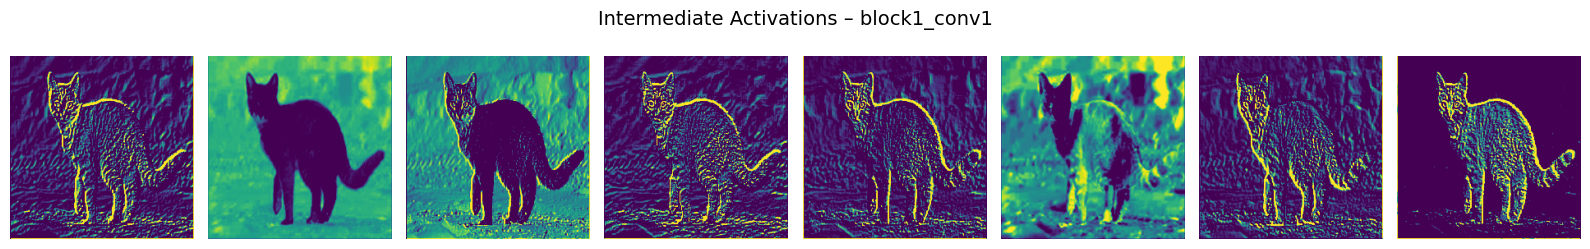

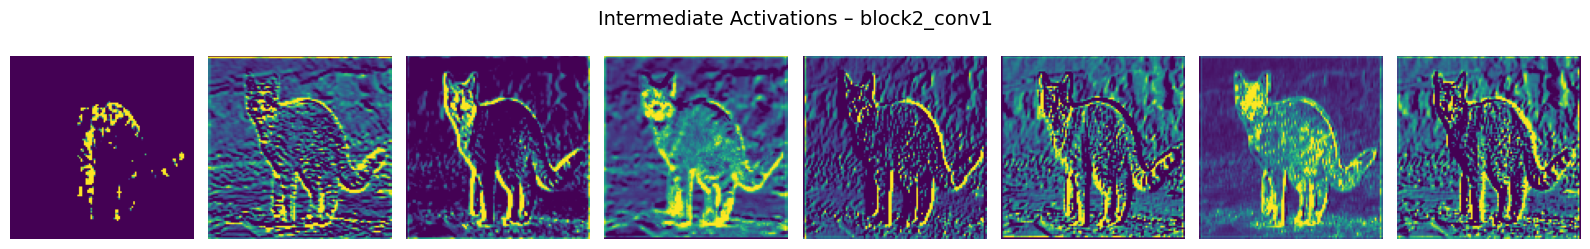

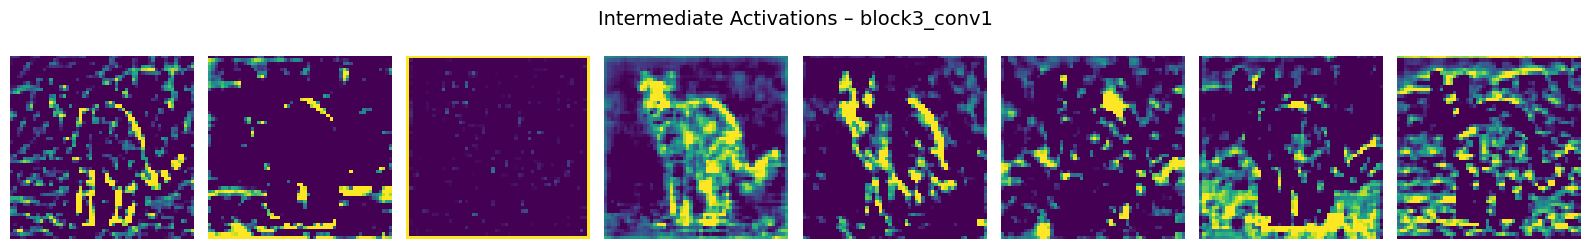

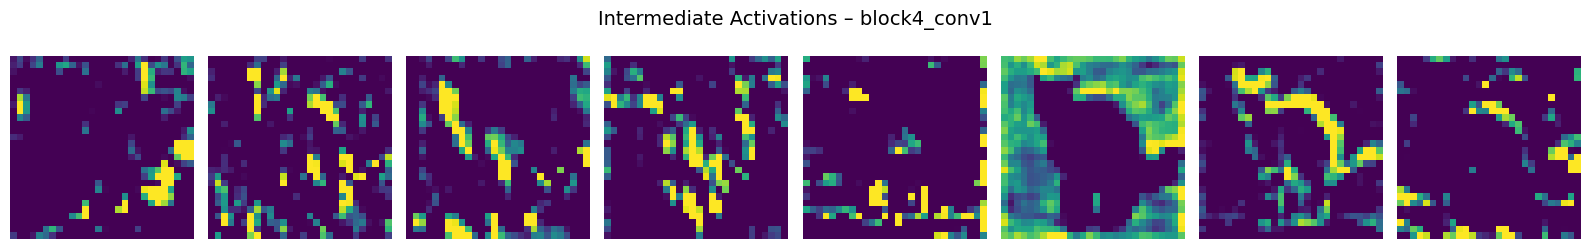

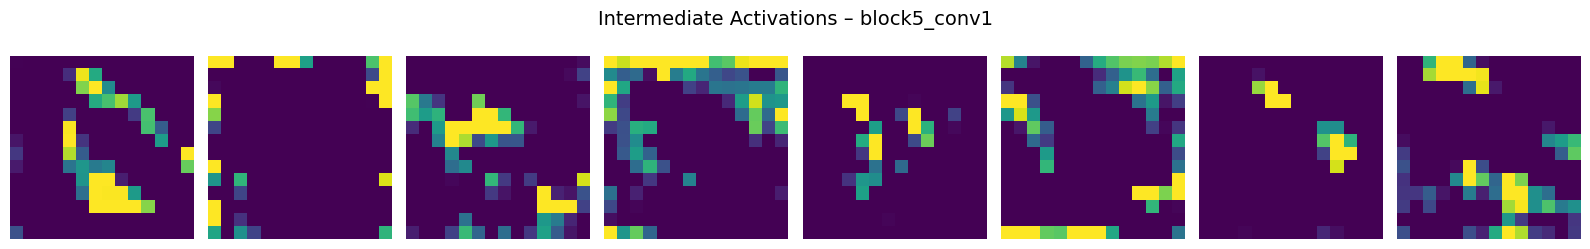

In [5]:
for layer_name, activation in zip(layer_names, activations):
    num_features = min(8, activation.shape[-1])

    plt.figure(figsize=(16, 2.5))
    plt.suptitle(f"Intermediate Activations – {layer_name}", fontsize=14)

    for i in range(num_features):
        plt.subplot(1, num_features, i + 1)
        feature_map = activation[0, :, :, i]

        feature_map = feature_map - feature_map.mean()
        std = feature_map.std()
        if std != 0:
            feature_map = feature_map / std
        feature_map = feature_map * 64 + 128
        feature_map = np.clip(feature_map, 0, 255).astype("uint8")

        plt.imshow(feature_map, cmap="viridis")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


### Observation – Intermediate Activations

It shows that the representation becomes more abstract as the image passes through deeper layers.

In the earlier convolutional layers, many activations still preserve information about edges, shapes, and the general structure of the original image. In the deeper layers, the feature maps look less like the original image because the network is representing more specialized and higher-level features.

This demonstrates that convolutional neural networks learn features hierarchically. Early layers learn simple visual patterns, while deeper layers combine those patterns into more complex representations.


# Part 2 – Visualizing ConvNet Filters

 I visualize what a single convolutional filter has learned to respond to.

Instead of starting with a real image, I begin with a generated image and use gradient ascent to modify the image so that a selected filter becomes as active as possible.

This process reveals the type of visual pattern that the selected filter prefers.


In [6]:
target_layer_name = "block3_conv1"
target_layer = model.get_layer(target_layer_name)

num_filters = target_layer.output.shape[-1]
filter_index = random.randint(0, int(num_filters) - 1)

print("Selected layer:", target_layer_name)
print("Randomly selected filter:", filter_index)


Selected layer: block3_conv1
Randomly selected filter: 157


In [7]:
feature_extractor = keras.Model(
    inputs=model.inputs,
    outputs=target_layer.output
)

@tf.function
def compute_loss(input_image):
    activation = feature_extractor(input_image)
    filter_activation = activation[:, 2:-2, 2:-2, filter_index]
    return tf.reduce_mean(filter_activation)

@tf.function
def gradient_ascent_step(input_image, learning_rate):
    with tf.GradientTape() as tape:
        tape.watch(input_image)
        loss = compute_loss(input_image)

    grads = tape.gradient(loss, input_image)
    grads = tf.math.l2_normalize(grads)

    input_image += learning_rate * grads
    return loss, input_image

generated_image = tf.random.uniform(
    shape=(1, 224, 224, 3),
    minval=0.4,
    maxval=0.6
)

iterations = 40
learning_rate = 10.0

for step in range(iterations):
    loss, generated_image = gradient_ascent_step(
        generated_image,
        learning_rate
    )

print("Final activation loss:", float(loss))


Final activation loss: 131.98268127441406


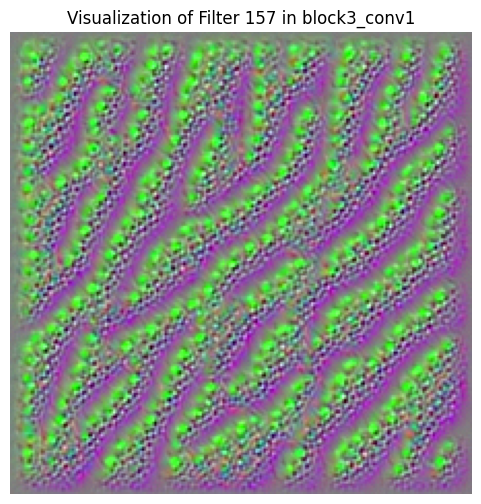

In [8]:
def deprocess_image(x):
    x = x[0]
    x = x - x.mean()
    x = x / (x.std() + 1e-5)
    x = x * 0.15
    x = x + 0.5
    x = np.clip(x, 0, 1)
    x = x * 255
    return np.clip(x, 0, 255).astype("uint8")

filter_image = deprocess_image(generated_image.numpy())

plt.figure(figsize=(6, 6))
plt.imshow(filter_image)
plt.axis("off")
plt.title(f"Visualization of Filter {filter_index} in {target_layer_name}")
plt.show()


### Observation – ConvNet Filter

The generated image is not expected to look like a normal photograph. Instead, it represents the visual pattern that strongly activates the selected filter.

It shows that individual filters specialize in detecting particular structures, textures, directions, or repeated patterns. Gradient ascent reveals those learned preferences by changing the input image in the direction that increases the filter activation.


# Part 3 – Visualizing Class Activation Heatmaps with Grad-CAM
 I use Grad-CAM to understand which region of the input image contributed most strongly to the model's final prediction.

Grad-CAM uses the gradients of the predicted class with respect to the final convolutional layer. The result is a heatmap showing the areas that were most important to the prediction.


In [9]:
classification_input = np.expand_dims(img_array.copy(), axis=0)
classification_input = preprocess_input(classification_input)

predictions = model.predict(classification_input, verbose=0)

top_prediction = decode_predictions(predictions, top=3)[0]

print("Top predictions:")
for _, label, score in top_prediction:
    print(f"{label}: {score:.4f}")


35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Top predictions:
lynx: 0.5817
coyote: 0.3677
timber_wolf: 0.0097


### Create the Grad-CAM heatmap

The last convolutional layer in VGG16 is `block5_conv3`. I use this layer because it contains high-level spatial features while still preserving information about where those features are located in the image.


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


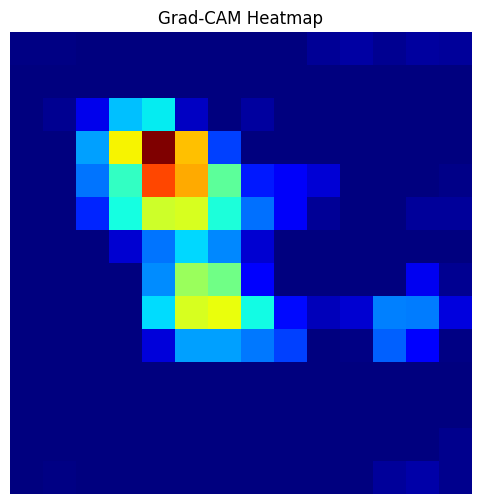

In [10]:
last_conv_layer_name = "block5_conv3"

grad_model = keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(last_conv_layer_name).output,
        model.output
    ]
)

with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(classification_input)
    predicted_class = tf.argmax(predictions[0])
    class_score = predictions[:, predicted_class]

grads = tape.gradient(class_score, conv_outputs)
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

conv_outputs = conv_outputs[0]
heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
heatmap = tf.squeeze(heatmap)

heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = heatmap.numpy()

plt.figure(figsize=(6, 6))
plt.imshow(heatmap, cmap="jet")
plt.axis("off")
plt.title("Grad-CAM Heatmap")
plt.show()


### Overlay the heatmap on the original image

The colored region indicates where the model focused most strongly when making its prediction. Warmer colors represent stronger influence on the final classification.


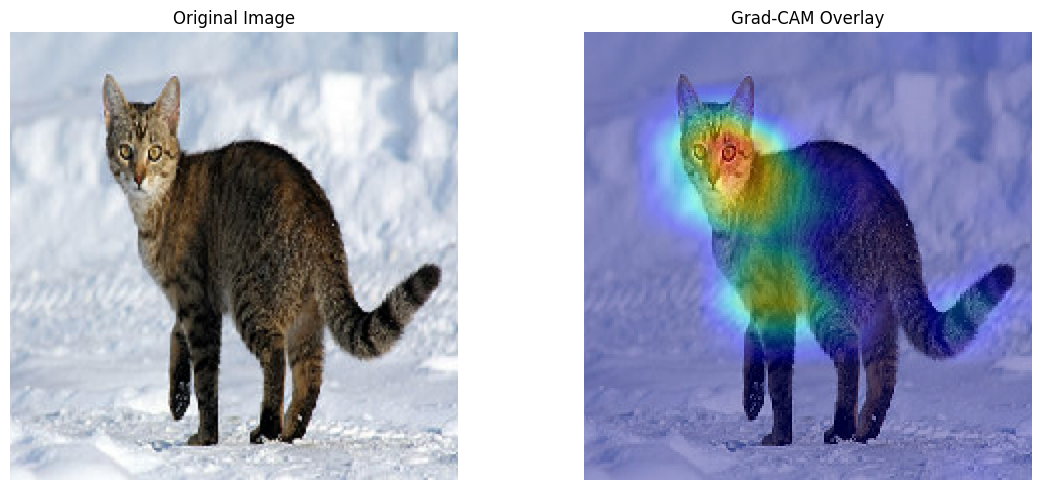

In [11]:
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

heatmap_uint8 = np.uint8(255 * heatmap_resized)
jet = plt.get_cmap("jet")
jet_colors = jet(np.arange(256))[:, :3]
jet_heatmap = jet_colors[heatmap_uint8]

original = np.array(img).astype("float32") / 255.0
overlay = 0.4 * jet_heatmap + 0.6 * original
overlay = np.clip(overlay, 0, 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.axis("off")
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.axis("off")
plt.title("Grad-CAM Overlay")

plt.tight_layout()
plt.show()


### Observation – Grad-CAM

The Grad-CAM heatmap highlights the regions of the image that contributed most strongly to the predicted class.

The important difference between this visualization and the previous sections is that Grad-CAM explains a specific prediction for a specific image. Intermediate activations show what happens throughout the network, and filter visualization shows what a single filter prefers. Grad-CAM connects the model's internal features to the final decision.

If the highlighted area corresponds to the main object in the image, it suggests that the network is using meaningful visual information for its prediction.


# Conclusion

 I used three visualization techniques to better understand what a convolutional neural network learns.

**Intermediate activation visualization** showed how an image is transformed as it passes through multiple convolutional layers. Earlier layers preserved simpler visual information, while deeper layers produced more abstract feature representations.

**ConvNet filter visualization** showed the visual pattern that maximally activates a randomly selected convolutional filter. This demonstrated how individual filters become specialized for different visual structures and textures.

**Grad-CAM** showed which areas of the original image contributed most strongly to the model's final prediction. This makes the final classification easier to interpret because it connects the prediction to a visible region of the input image.

Overall, these methods help make convolutional neural networks less of a black box by showing what features they detect, how those features change across layers, and which parts of an image influence the final prediction.
